# BCFCM
A LOT LIKE FCM WITH ADDITIONAL 'B' WHICH CAN BE CATERED DOWN WITH EASE

### Algorithm(Alternate Minimization Stratergy)-
1-UPDATE V , FIXING U AND B
2-UPDATE U , FIXING V AND B
3-UPDATE B , FIXING V AND U

ALOT LIKE BCFCM WITHOUT SPATIAL BUT WE HAVE TO FORM THIS NEIGHBOURHOOD MATRIX AS WELL
THE PROPERTIES OF NEIGHBOURHOOD MATRIX MUST BE -
1- IS A POINT IS NEIGHBOUR OF OTHER THEN THE OTHER POINT MUST BE IT'S NEIGHBOUR AS WELL
2- TO RANDOMLY GENERATE IT , MAKE A SYMMETRIC MATRIX OF ALL NON ZERO ENTRIES 1;
WHERE 1 SYMBOLISES NEIGHBOUR AND 0 SYMBOLIZES NOT NEIGHBOUR

> ## done according to the paper , not according to reality


In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import netcdf_file
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from bcfcm import Run

In [2]:
def load_slice(name, s=90):
    f = netcdf_file(os.path.join('..', name), 'r', mmap=False)
    raw = f.variables['image'].data
    vmin = float(f.variables['image-min'].data[s])
    vmax = float(f.variables['image-max'].data[s])
    f.close()
    slc = vmin + (raw[:, :, s].astype(float) / 65535.0) * (vmax - vmin)
    return (slc - slc.min()) / (slc.max() - slc.min() + 1e-8)

img_clean = load_slice('clean.mnc')
img_mod   = load_slice('moderate.mnc')
img_hard  = load_slice('hard.mnc')

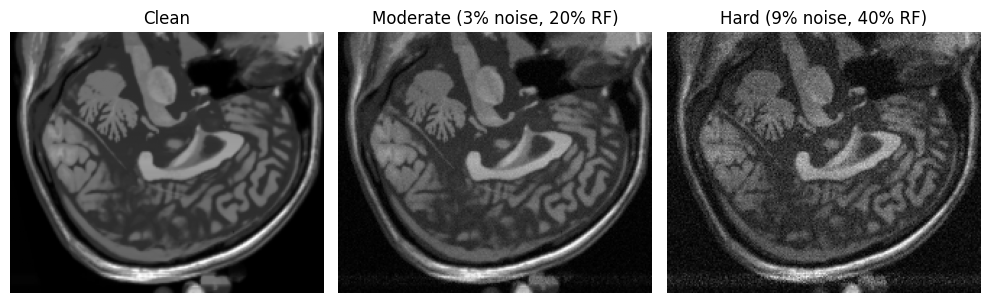

In [3]:
plt.figure(figsize=(10, 3.5))
for i, (im, t) in enumerate([(img_clean, 'Clean'), (img_mod, 'Moderate (3% noise, 20% RF)'), (img_hard, 'Hard (9% noise, 40% RF)')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap='gray')
    plt.title(t)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
# clean baseline
seg_clean, U_clean, V_clean, B_clean = Run(img_clean, c=3, m=2.0, a_=0.2)
print("Clean centroids:", V_clean.ravel().round(3))
print("Cluster sizes:", [int((seg_clean == k).sum()) for k in range(3)])

Clean centroids: [0.061 0.212 0.374]
Cluster sizes: [10541, 16859, 11877]


In [5]:
# moderate
seg_mod, U_mod, V_mod, B_mod = Run(img_mod, c=3, m=2.0, a_=1.0)
print("Moderate centroids:", V_mod.ravel().round(3))
print("Cluster sizes:", [int((seg_mod == k).sum()) for k in range(3)])

Moderate centroids: [0.09  0.218 0.36 ]
Cluster sizes: [11106, 16532, 11639]


In [6]:
# hard
seg_hard, U_hard, V_hard, B_hard = Run(img_hard, c=3, m=2.0, a_=2.0)
print("Hard centroids:", V_hard.ravel().round(3))
print("Cluster sizes:", [int((seg_hard == k).sum()) for k in range(3)])

Hard centroids: [0.141 0.203 0.313]
Cluster sizes: [17659, 11811, 9807]


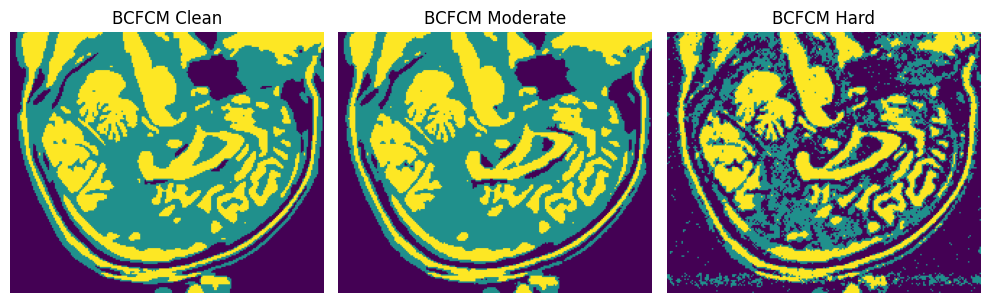

In [7]:
plt.figure(figsize=(10, 3.5))
for i, (s, t) in enumerate([(seg_clean, 'BCFCM Clean'), (seg_mod, 'BCFCM Moderate'), (seg_hard, 'BCFCM Hard')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(s, cmap='viridis')
    plt.title(t)
    plt.axis('off')
plt.tight_layout()
plt.show()

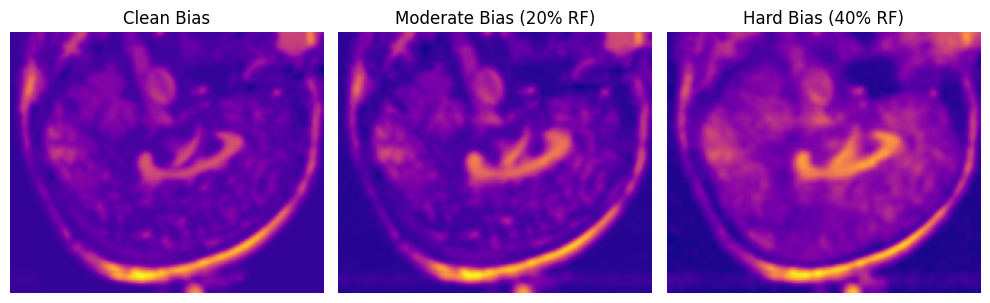

In [8]:
plt.figure(figsize=(10, 3.5))
for i, (b_arr, t) in enumerate([(B_clean, 'Clean Bias'), (B_mod, 'Moderate Bias (20% RF)'), (B_hard, 'Hard Bias (40% RF)')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(b_arr.reshape(img_clean.shape), cmap='plasma')
    plt.title(t)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
def match_labels(seg, ref, c=3):
    cost = np.zeros((c, c))
    for i in range(c):
        for j in range(c):
            cost[i, j] = -((seg == i) & (ref == j)).sum()
    row, col = linear_sum_assignment(cost)
    return np.vectorize(dict(zip(row, col)).get)(seg)

def dice_score(seg, ref, c=3):
    scores = []
    for k in range(c):
        p, r = (seg == k), (ref == k)
        scores.append(2.0 * (p & r).sum() / (p.sum() + r.sum() + 1e-8))
    return np.mean(scores)

ref = seg_clean
seg_m = match_labels(seg_mod, ref)
seg_h = match_labels(seg_hard, ref)

In [10]:
print(f"{'Condition':<25} {'Dice':>7} {'ARI':>7} {'NMI':>7} {'ASA':>7}")
print("-" * 55)
for name, s in [('Clean (baseline)', ref), ('Moderate (3% noise)', seg_m), ('Hard (9% noise)', seg_h)]:
    d = dice_score(s, ref)
    ari = adjusted_rand_score(ref.ravel(), s.ravel())
    nmi = normalized_mutual_info_score(ref.ravel(), s.ravel())
    asa = (s.ravel() == ref.ravel()).mean() * 100
    print(f"{name:<25} {d:>7.3f} {ari:>7.3f} {nmi:>7.3f} {asa:>6.1f}%")

Condition                    Dice     ARI     NMI     ASA
-------------------------------------------------------
Clean (baseline)            1.000   1.000   1.000  100.0%
Moderate (3% noise)         0.960   0.876   0.835   95.9%
Hard (9% noise)             0.719   0.379   0.448   70.7%
